# 2. Onsager's kinetic equations

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapter 1; matrices

A real system has many variables, and the friction on one of them usually depends on
how the others move. A rod falling through a liquid drifts sideways. Two spheres fall
faster together than apart, because each is carried along by the flow the other
creates. This chapter extends the Rayleighian of Chapter 1 to several variables,
shows that the equations it gives have a definite form, and identifies the physical
law that makes the extension possible: the friction matrix is symmetric. That law is
Onsager's reciprocal relation.

The checks in this chapter are a closed-form result for the drift of a slender rod,
the symmetry of the velocities computed for two different loadings, and the energy
balance $\dot A = -2\Phi$ along a numerical solution.

In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np
import sympy as sp
from scipy.integrate import cumulative_trapezoid, solve_ivp

try:
    import onsager as on
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import onsager as on

on.use_style()

## 2.1 Several variables

Let the state be described by variables $x = (x_1, \dots, x_n)$: positions of
particles, the height of a meniscus, the radius of a droplet. The free energy is a
function $A(x)$. If the variables change at the rates $\dot x_i$, the free energy
changes at the rate

$$ \dot A = \sum_i \frac{\partial A}{\partial x_i}\,\dot x_i . $$

In slow viscous motion the velocity of the surrounding fluid is, at each instant,
proportional to the rates $\dot x_i$ (the Stokes equation is linear), and the energy
dissipated is quadratic in the velocity. The dissipation function is therefore a
quadratic form in the rates,

$$ \Phi = \frac12\sum_{i,j}\zeta_{ij}(x)\,\dot x_i\dot x_j , \tag{2.1} $$

with coefficients that may depend on the state. Since the dissipation is positive
for any motion, the matrix $\zeta$ is positive definite. The Rayleighian is

$$ R(\dot x; x) = \frac12\sum_{i,j}\zeta_{ij}\,\dot x_i\dot x_j
                 + \sum_i \frac{\partial A}{\partial x_i}\,\dot x_i . \tag{2.2} $$

Setting $\partial R/\partial\dot x_i = 0$ for each $i$:

$$ \frac12\sum_j \big(\zeta_{ij} + \zeta_{ji}\big)\dot x_j + \frac{\partial A}{\partial x_i} = 0 . \tag{2.3} $$

Only the symmetric part of $\zeta$ appears. In a quadratic form the antisymmetric part
cancels, so one may as well take $\zeta_{ij} = \zeta_{ji}$ in Eq. (2.1), and Eq. (2.3)
becomes

$$ \boxed{\;\sum_j \zeta_{ij}\,\dot x_j = -\frac{\partial A}{\partial x_i}\;} \tag{2.4} $$

These are **Onsager's kinetic equations**. The right-hand side is the thermodynamic
force that pushes $x_i$ towards lower free energy. The left-hand side is the friction
force that the medium exerts on $x_i$ when all the variables move. Solving for the
rates with the inverse matrix $\mu = \zeta^{-1}$, the mobility matrix,

$$ \dot x_i = -\sum_j \mu_{ij}\,\frac{\partial A}{\partial x_j} . \tag{2.5} $$

### What the symmetry means

Equation (2.4) is a force balance, and one could have started from it: measure, or
calculate from hydrodynamics, the friction force on variable $i$ when variable $j$
moves, call the coefficient $\zeta_{ij}$, and write the balance. Nothing in that
procedure says that $\zeta_{ij}$ should equal $\zeta_{ji}$: that the force on $i$ due
to the motion of $j$ equals the force on $j$ due to the same motion of $i$.

But it does. Onsager showed in 1931 that the symmetry follows from the time-reversal
symmetry of the microscopic motion, for any system close to equilibrium (in the
absence of magnetic fields and overall rotation, which break that symmetry). In slow
viscous flow the same result is known as the Lorentz reciprocal theorem. It is a law
of nature, not a convention, and it is what allows the force balance to be written
as a minimum principle: a force balance with a non-symmetric friction matrix is not
the stationarity condition of any Rayleighian, since the Rayleighian only sees the
symmetric part.

### What positivity means

Multiply Eq. (2.4) by $\dot x_i$ and sum:

$$ \dot A = \sum_i \frac{\partial A}{\partial x_i}\dot x_i
          = -\sum_{i,j}\zeta_{ij}\dot x_i\dot x_j = -2\Phi \le 0 . \tag{2.6} $$

The free energy can only decrease, and it stops decreasing only when all the rates
vanish, which by Eq. (2.4) is where $\partial A/\partial x_i = 0$: equilibrium. Any
model derived from a Rayleighian with a positive dissipation function relaxes to the
minimum of its free energy. This is the second law, built in.

### In code

`on.kinetic_equations(A, Phi, x, xdot)` carries out the minimisation symbolically:
it forms the Rayleighian, differentiates with respect to each rate and solves the
linear equations. For the particle of Chapter 1 in a harmonic trap:

In [2]:
x, v = sp.symbols("x v")
zeta, k = sp.symbols("zeta k", positive=True)
print(on.kinetic_equations(A=k * x**2 / 2, Phi=zeta * v**2 / 2, x=[x], xdot=[v]))

{v: -k*x/zeta}


## 2.2 A rod that falls sideways

A thin rod moving through a viscous liquid meets less resistance along its length
than across it. If $\mathbf u$ is the unit vector along the rod, and the rod moves
with velocity $\mathbf v$ without rotating, the friction force is
$-\zeta_\parallel\mathbf v_\parallel - \zeta_\perp\mathbf v_\perp$, and the dissipation
function is

$$ \Phi = \tfrac12\zeta_\parallel(\mathbf u\cdot\mathbf v)^2
        + \tfrac12\zeta_\perp\big[v^2 - (\mathbf u\cdot\mathbf v)^2\big] . $$

In the limit of a very slender rod $\zeta_\perp = 2\zeta_\parallel$. Let the rod make
an angle $\theta$ with the vertical, $\mathbf u = (\sin\theta, \cos\theta)$ in the
$(x, z)$ plane with $z$ upwards, and let its weight (less buoyancy) be $F$, so that
$A = Fz$. A uniform rod settling in an unbounded liquid feels no torque and keeps its
orientation, so $\theta$ is a constant and the variables are $x$ and $z$.

In terms of $x$ and $z$ the friction matrix is not diagonal, and the kinetic
equations couple the two directions: a vertical force produces a horizontal
velocity.

In [3]:
X, Z, vx, vz = sp.symbols("X Z v_x v_z")
theta, zpar, zperp, F = sp.symbols("theta zeta_par zeta_perp F", positive=True)

u = sp.Matrix([sp.sin(theta), sp.cos(theta)])
vel = sp.Matrix([vx, vz])
along = (u.T * vel)[0]
Phi_rod = zpar * along**2 / 2 + zperp * (vel.dot(vel) - along**2) / 2

print("friction matrix in (x, z):")
sp.pprint(sp.simplify(on.friction_matrix(Phi_rod, [vx, vz])))

rod = on.kinetic_equations(A=F * Z, Phi=Phi_rod, x=[X, Z], xdot=[vx, vz])
print("\nv_x =", sp.factor(rod[vx]))
print("v_z =", sp.factor(sp.trigsimp(rod[vz])))

tan_alpha = sp.simplify(rod[vx] / rod[vz])           # drift angle alpha, from the vertical
print("\ntan(alpha) =", tan_alpha)

friction matrix in (x, z):
⎡        2               2       (ζₚₐᵣ - ζₚₑᵣₚ)⋅sin(2⋅θ)   ⎤
⎢ζₚₐᵣ⋅sin (θ) + ζₚₑᵣₚ⋅cos (θ)    ───────────────────────   ⎥
⎢                                           2              ⎥
⎢                                                          ⎥
⎢  (ζₚₐᵣ - ζₚₑᵣₚ)⋅sin(2⋅θ)             2               2   ⎥
⎢  ───────────────────────     ζₚₐᵣ⋅cos (θ) + ζₚₑᵣₚ⋅sin (θ)⎥
⎣             2                                            ⎦



v_x = F*(zeta_par - zeta_perp)*sin(2*theta)/(2*zeta_par*zeta_perp)
v_z = -F*(zeta_par*sin(theta)**2 - zeta_perp*sin(theta)**2 + zeta_perp)/(zeta_par*zeta_perp)

tan(alpha) = (-zeta_par/2 + zeta_perp/2)*sin(2*theta)/(zeta_par*sin(theta)**2 - zeta_perp*sin(theta)**2 + zeta_perp)


The rod sinks ($v_z < 0$) and at the same time slides sideways, towards the side
to which its lower end points ($v_x < 0$ here). Its path makes an angle $\alpha$ with
the vertical given by

$$ \tan\alpha = \frac{(\zeta_\perp - \zeta_\parallel)\sin\theta\cos\theta}
                     {\zeta_\perp\cos^2\theta + \zeta_\parallel\sin^2\theta} . $$

For the slender rod, $\zeta_\perp = 2\zeta_\parallel$, this is
$\tan\alpha = \tan\theta/(2 + \tan^2\theta)$, which is largest at
$\tan\theta = \sqrt2$ ($\theta = 54.7^\circ$), where $\tan\alpha = \sqrt2/4$, that is,
$\alpha = \arcsin\tfrac13 = 19.5^\circ$. No rod, however long, drifts more steeply
than that. The cell below checks the closed form against a direct numerical search,
and checks the reciprocal relation: the horizontal velocity produced by a vertical
force equals the vertical velocity produced by the same force applied horizontally.

In [4]:
drift = sp.lambdify((theta, zperp, zpar), sp.atan(tan_alpha))
th = np.linspace(0, np.pi / 2, 200001)
alpha = drift(th, 2.0, 1.0)
i = np.argmax(alpha)
print(f"largest drift angle (numerical search): {np.degrees(alpha[i]):.4f} deg at theta = {np.degrees(th[i]):.2f} deg")
print(f"closed form:                            {np.degrees(math.asin(1/3)):.4f} deg at theta = "
      f"{np.degrees(math.atan(math.sqrt(2))):.2f} deg")

# reciprocity: the same force applied vertically, then horizontally
vertical = on.kinetic_equations(F * Z, Phi_rod, [X, Z], [vx, vz])
horizontal = on.kinetic_equations(F * X, Phi_rod, [X, Z], [vx, vz])
print("\nv_x under a vertical force  :", sp.factor(vertical[vx]))
print("v_z under a horizontal force:", sp.factor(horizontal[vz]))
print("difference:", sp.simplify(vertical[vx] - horizontal[vz]))

largest drift angle (numerical search): 19.4712 deg at theta = 54.74 deg
closed form:                            19.4712 deg at theta = 54.74 deg



v_x under a vertical force  : F*(zeta_par - zeta_perp)*sin(2*theta)/(2*zeta_par*zeta_perp)
v_z under a horizontal force: F*(zeta_par - zeta_perp)*sin(2*theta)/(2*zeta_par*zeta_perp)
difference: 0


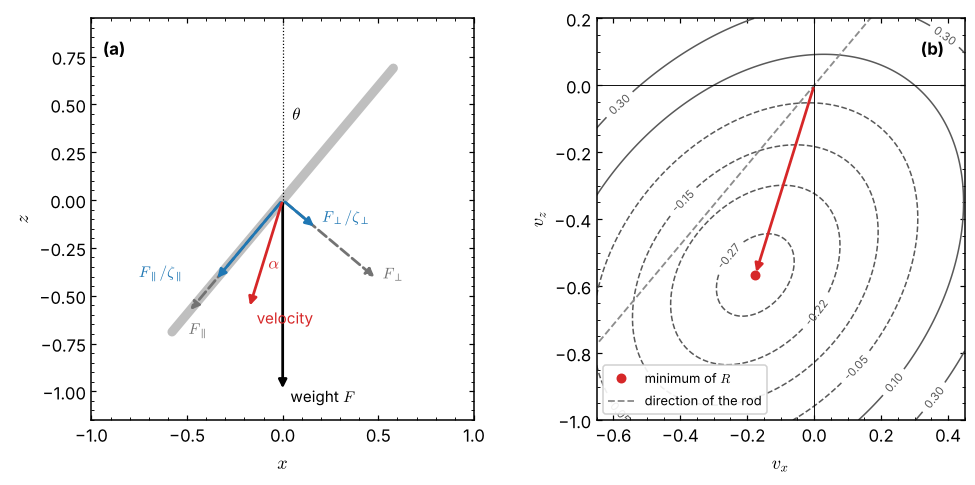

drift angle at theta = 40 deg: 17.24 deg


In [5]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 4.3))
th0 = np.radians(40.0)
u0 = np.array([np.sin(th0), np.cos(th0)])
force = np.array([0.0, -1.0])
f_par = (force @ u0) * u0
f_perp = force - f_par
zpar0, zperp0 = 1.4, 2.8                           # any values with zeta_perp = 2 zeta_par
v_par, v_perp = f_par / zpar0, f_perp / zperp0
v_tot = v_par + v_perp


def arrow(ax, start, vec, color, label, shift=(0.03, 0.0), ls="-"):
    ax.annotate("", xy=start + vec, xytext=start, arrowprops=dict(arrowstyle="-|>", color=color, lw=1.8, ls=ls))
    ax.text(*(start + vec + np.array(shift)), label, color=color, fontsize=10, va="center")


ax1.plot([-0.9 * u0[0], 0.9 * u0[0]], [-0.9 * u0[1], 0.9 * u0[1]], color="0.75", lw=6, solid_capstyle="round", zorder=0)
origin = np.zeros(2)
arrow(ax1, origin, force, "k", "weight $F$", shift=(0.04, -0.03))
arrow(ax1, origin, f_par, "0.45", r"$F_\parallel$", shift=(0.0, -0.09), ls="--")
arrow(ax1, origin, f_perp, "0.45", r"$F_\perp$", shift=(0.03, 0.03), ls="--")
arrow(ax1, origin, v_par, "C0", r"$F_\parallel/\zeta_\parallel$", shift=(-0.4, 0.04))
arrow(ax1, origin, v_perp, "C0", r"$F_\perp/\zeta_\perp$", shift=(0.03, 0.06))
arrow(ax1, origin, v_tot, "C3", "velocity", shift=(0.04, -0.05))
ax1.plot([0, 0], [0, 1.0], "k:", lw=0.8)
ax1.text(0.05, 0.42, r"$\theta$", fontsize=11)
ax1.text(-0.075, -0.36, r"$\alpha$", color="C3", fontsize=11)
ax1.set_xlim(-1.0, 1.0); ax1.set_ylim(-1.15, 0.95); ax1.set_aspect("equal")
ax1.set_xlabel("$x$"); ax1.set_ylabel("$z$"); on.panel_label(ax1, "(a)")

VX, VZ = np.meshgrid(np.linspace(-0.65, 0.45, 300), np.linspace(-1.0, 0.2, 300))
along0 = VX * u0[0] + VZ * u0[1]
R_rod = 0.5 * zpar0 * along0**2 + 0.5 * zperp0 * (VX**2 + VZ**2 - along0**2) + VZ       # Phi + F v_z
cs = ax2.contour(VX, VZ, R_rod, levels=[-0.27, -0.22, -0.15, -0.05, 0.1, 0.3], colors="0.35", linewidths=1)
ax2.clabel(cs, fmt="%.2f", fontsize=7.5)
ax2.plot(*v_tot, "o", color="C3", label=r"minimum of $R$")
ax2.annotate("", xy=v_tot, xytext=(0, 0), arrowprops=dict(arrowstyle="-|>", color="C3", lw=1.8))
ax2.plot([-u0[0], u0[0]], [-u0[1], u0[1]], "--", color="0.55", lw=1.2, label="direction of the rod")
ax2.axvline(0, color="k", lw=0.6); ax2.axhline(0, color="k", lw=0.6)
ax2.set_xlim(-0.65, 0.45); ax2.set_ylim(-1.0, 0.2); ax2.set_aspect("equal")
ax2.set_xlabel("$v_x$"); ax2.set_ylabel("$v_z$")
ax2.legend(loc="lower left", fontsize=8.5, frameon=True, framealpha=0.9); on.panel_label(ax2, "(b)", x=0.88)
plt.show()
print(f"drift angle at theta = 40 deg: {np.degrees(np.arctan(v_tot[0] / v_tot[1])):.2f} deg")

**Figure 2.1.** A rod inclined at $\theta = 40^\circ$, with $\zeta_\perp = 2\zeta_\parallel$.
**(a)** The weight is resolved along and across the rod. Each component produces a
velocity in its own direction, but the component across the rod meets twice the
friction, so the resultant velocity (red) is tilted away from the vertical towards
the direction of the rod. **(b)** The same result as a minimum: contours of the
Rayleighian in the plane of the two velocity components. The contours are ellipses,
elongated along the rod because motion in that direction costs least, and their
centre, the minimum, lies to one side of the vertical axis.

## 2.3 Two spheres that fall together

Two equal spheres of radius $a$ are joined by a spring and released in a viscous
liquid, one above the other. Let $z_1$ and $z_2$ be their heights, $r = z_2 - z_1$
their separation, $W$ the weight of each, and

$$ A = W(z_1 + z_2) + \tfrac12 k\,(r - r_0)^2 . $$

A sphere moving through a liquid drags the liquid with it, and the other sphere sits
in that flow. For spheres far apart ($r \gg a$) and motion along the line of
centres, a force $f$ on one sphere gives the other a velocity $f/(4\pi\eta r)$, in
addition to the velocity $f/(6\pi\eta a)$ it gives to itself. The mobility matrix is
therefore

$$ \mu = \frac{1}{6\pi\eta a}\begin{pmatrix} 1 & 3a/2r \\ 3a/2r & 1 \end{pmatrix} , $$

symmetric, as it must be, and dependent on the state through $r$. It is positive
definite for $r > 3a/2$, which always holds for spheres that do not overlap. The
friction matrix is its inverse, and $\Phi = \tfrac12\dot{\mathbf z}^{\mathsf T}\mu^{-1}\dot{\mathbf z}$.

Before computing, Eq. (2.5) can be read off by hand. The forces are
$f_1 = -W + k(r - r_0)$ and $f_2 = -W - k(r - r_0)$. Then

$$ \dot z_1 + \dot z_2 = -2W(\mu_{11} + \mu_{12}) , \qquad
   \dot r = \dot z_2 - \dot z_1 = -2k(\mu_{11} - \mu_{12})(r - r_0) . \tag{2.7} $$

The pair falls faster than a single sphere, by the factor $1 + 3a/2r$, and the weight
has no effect on the separation, which relaxes under the spring alone, more slowly
than it would without the hydrodynamic interaction. The cell below obtains the
equations from $A$ and $\Phi$, integrates them, and checks Eq. (2.7) and the energy
balance (2.6). Units: $a = 1$, $6\pi\eta a = 1$. The cell takes $W = 1$, $k = 0.5$ and
$r_0 = 4$, and releases the spheres at $r = 10$.

In [6]:
z1, z2, w1, w2 = sp.symbols("z1 z2 w1 w2")
W, ks, r0 = sp.symbols("W k r0", positive=True)

r = z2 - z1
mobility = sp.Matrix([[1, sp.Rational(3, 2) / r], [sp.Rational(3, 2) / r, 1]])
rates = sp.Matrix([w1, w2])
Phi_pair = (rates.T * mobility.inv() * rates)[0] / 2
A_pair = W * (z1 + z2) + ks * (r - r0) ** 2 / 2

pair = on.kinetic_equations(A_pair, Phi_pair, [z1, z2], [w1, w2])
print("d(z1 + z2)/dt =", sp.factor(sp.simplify(pair[w1] + pair[w2])))
print("d(z2 - z1)/dt =", sp.factor(sp.simplify(pair[w2] - pair[w1])))

values = {W: 1.0, ks: 0.5, r0: 4.0}
rhs = on.rate_function(pair, [z1, z2], [w1, w2], values)
t = np.linspace(0, 12, 4801)
sol = solve_ivp(rhs, (0, t[-1]), [0.0, 10.0], t_eval=t, rtol=1e-11, atol=1e-13)
Z1, Z2 = sol.y
sep = Z2 - Z1

A_num = sp.lambdify((z1, z2), A_pair.subs(values))(Z1, Z2)
speeds = np.array(rhs(0, [Z1, Z2]))
two_Phi = 2 * sp.lambdify((z1, z2, w1, w2), Phi_pair)(Z1, Z2, *speeds)
dissipated = cumulative_trapezoid(two_Phi, t, initial=0.0)

fall = -(speeds[0] + speeds[1]) / 2
print(f"\nfall speed / single-sphere speed at r = 10: {fall[0]:.4f}   (1 + 3/2r = {1 + 1.5 / 10:.4f})")
print(f"                                 at the end: {fall[-1]:.4f}   (1 + 3/2r = {1 + 1.5 / sep[-1]:.4f})")
print(f"largest |A(0) - A(t) - integral of 2 Phi|: {on.sup_error(A_num[0] - A_num, dissipated):.1e}"
      f"   (A falls by {A_num[0] - A_num[-1]:.2f})")

d(z1 + z2)/dt = -W*(2*z1 - 2*z2 - 3)/(z1 - z2)
d(z2 - z1)/dt = k*(r0 + z1 - z2)*(2*z1 - 2*z2 + 3)/(z1 - z2)

fall speed / single-sphere speed at r = 10: 1.1500   (1 + 3/2r = 1.1500)
                                 at the end: 1.3748   (1 + 3/2r = 1.3748)
largest |A(0) - A(t) - integral of 2 Phi|: 1.4e-05   (A falls by 41.08)


The symbolic result reproduces Eq. (2.7), the pair falls 15 % faster than a single
sphere at $r = 10a$ and faster still as the spring pulls the spheres together, and
the free energy lost equals the energy dissipated to the accuracy of the
integration. The mobility used here is the leading term for well-separated spheres;
it is not accurate when the gap between the spheres is comparable to their radius.

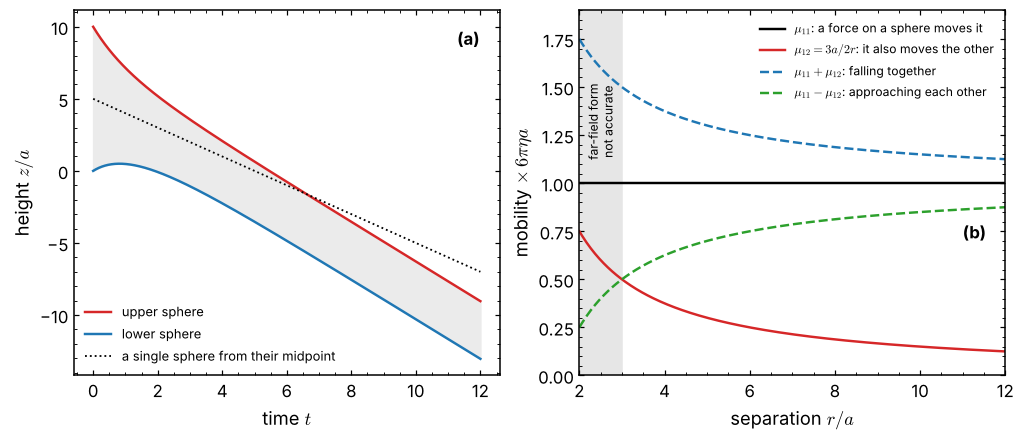

In [7]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(9.2, 3.9))

ax1.plot(t, Z2, color="C3", label="upper sphere")
ax1.plot(t, Z1, color="C0", label="lower sphere")
ax1.plot(t, 0.5 * (Z1[0] + Z2[0]) - t, "k:", lw=1.2, label="a single sphere from their midpoint")
ax1.fill_between(t, Z1, Z2, color="0.92")
ax1.set_xlabel("time $t$"); ax1.set_ylabel("height $z/a$")
ax1.legend(loc="lower left", fontsize=8.5); on.panel_label(ax1, "(a)", x=0.9)

rr = np.linspace(2, 12, 300)
ax2.plot(rr, np.ones_like(rr), "k-", label=r"$\mu_{11}$: a force on a sphere moves it")
ax2.plot(rr, 1.5 / rr, color="C3", label=r"$\mu_{12} = 3a/2r$: it also moves the other")
ax2.plot(rr, 1 + 1.5 / rr, "--", color="C0", label=r"$\mu_{11} + \mu_{12}$: falling together")
ax2.plot(rr, 1 - 1.5 / rr, "--", color="C2", label=r"$\mu_{11} - \mu_{12}$: approaching each other")
ax2.axvspan(2, 3, color="0.9"); ax2.text(2.5, 1.32, "far-field form\nnot accurate", fontsize=8, ha="center", va="center", rotation=90)
ax2.set_xlim(2, 12); ax2.set_ylim(0, 1.9)
ax2.set_xlabel("separation $r/a$"); ax2.set_ylabel(r"mobility $\times\,6\pi\eta a$")
ax2.legend(loc="upper right", fontsize=8); on.panel_label(ax2, "(b)", x=0.9, y=0.42)
plt.show()

**Figure 2.2.** **(a)** Heights of the two spheres. Both fall faster than a single
sphere would (dotted line), and the gap between them closes under the spring.
**(b)** The elements of the mobility matrix. The off-diagonal element decays only as
$1/r$: hydrodynamic interaction has a long range. Motion in which the spheres move
together is helped by the interaction; relative motion is hindered, because each
sphere carries the other along in its own direction of motion.

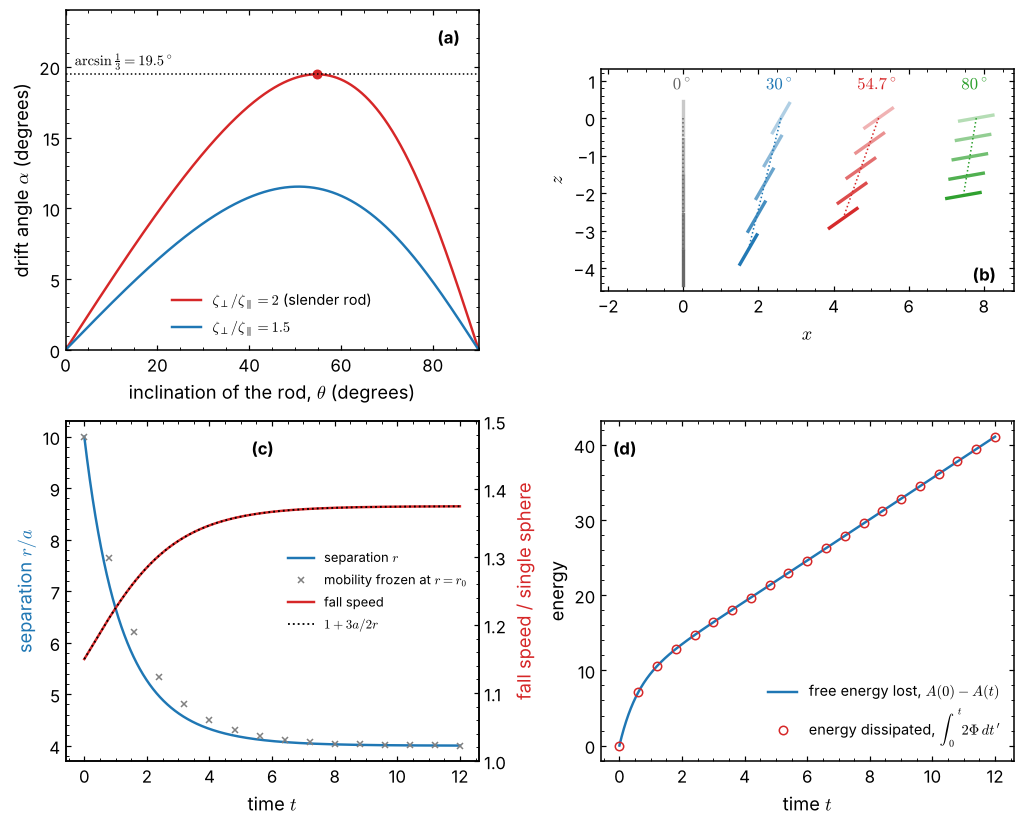

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.4))

ax = axes[0, 0]
thd = np.degrees(th)
for ratio, c, lab in ((2.0, "C3", r"$\zeta_\perp/\zeta_\parallel = 2$ (slender rod)"),
                      (1.5, "C0", r"$\zeta_\perp/\zeta_\parallel = 1.5$")):
    ax.plot(thd, np.degrees(drift(th, ratio, 1.0)), color=c, label=lab)
ax.plot(np.degrees(math.atan(math.sqrt(2))), np.degrees(math.asin(1 / 3)), "o", color="C3")
ax.axhline(np.degrees(math.asin(1 / 3)), color="k", ls=":", lw=1)
ax.text(2, 20.1, r"$\arcsin\frac{1}{3} = 19.5^\circ$", fontsize=9.5)
ax.set_xlabel(r"inclination of the rod, $\theta$ (degrees)"); ax.set_ylabel(r"drift angle $\alpha$ (degrees)")
ax.set_xlim(0, 90); ax.set_ylim(0, 24); ax.legend(loc="lower center"); on.panel_label(ax, "(a)", x=0.9)

ax = axes[0, 1]
vx_num = sp.lambdify(theta, rod[vx].subs({zpar: 1, zperp: 2, F: 1}))
vz_num = sp.lambdify(theta, rod[vz].subs({zpar: 1, zperp: 2, F: 1}))
for deg, c in ((0, "0.4"), (30, "C0"), (54.7, "C3"), (80, "C2")):
    a = np.radians(deg)
    X0 = 2.6 * [0, 30, 54.7, 80].index(deg)
    for s in np.linspace(0, 4.0, 5):
        cx, cz = X0 + vx_num(a) * s, vz_num(a) * s
        ax.plot([cx - 0.45 * np.sin(a), cx + 0.45 * np.sin(a)], [cz - 0.45 * np.cos(a), cz + 0.45 * np.cos(a)],
                color=c, lw=2.2, alpha=0.35 + 0.16 * s)
    ax.plot([X0, X0 + vx_num(a) * 4], [0, vz_num(a) * 4], ":", color=c, lw=1)
    ax.text(X0, 0.75, rf"${deg:g}^\circ$", ha="center", color=c)
ax.set_aspect("equal"); ax.set_xlabel("$x$"); ax.set_ylabel("$z$")
ax.set_xlim(-2.2, 8.8); ax.set_ylim(-4.6, 1.3); on.panel_label(ax, "(b)", x=0.9, y=0.12)

ax = axes[1, 0]
ax.plot(t, sep, color="C0", label="separation $r$")
ax.plot(t[::320], 4 + 6 * np.exp(-2 * 0.5 * (1 - 1.5 / 4) * t[::320]), "x", color="0.5", ms=4,
        label=r"mobility frozen at $r = r_0$")
ax.set_xlabel("time $t$"); ax.set_ylabel("separation $r/a$", color="C0")
ax2 = ax.twinx()
ax2.plot(t, fall, color="C3", label="fall speed")
ax2.plot(t, 1 + 1.5 / sep, "k:", lw=1.2, label="$1 + 3a/2r$")
ax2.set_ylabel("fall speed / single sphere", color="C3"); ax2.set_ylim(1.0, 1.5)
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="center right", fontsize=8.5); on.panel_label(ax, "(c)", x=0.45)

ax = axes[1, 1]
ax.plot(t, A_num[0] - A_num, color="C0", label="free energy lost, $A(0) - A(t)$")
ax.plot(t[::240], dissipated[::240], "o", color="C3", mfc="none", label=r"energy dissipated, $\int_0^t 2\Phi\,dt'$")
ax.set_xlabel("time $t$"); ax.set_ylabel("energy")
ax.legend(loc="lower right"); on.panel_label(ax, "(d)")
plt.show()

**Figure 2.3.** **(a)** Drift angle of a settling rod as a function of its inclination. For a
slender rod it cannot exceed $\arcsin\frac13$. **(b)** Rods at four inclinations,
drawn at equal intervals of time: the vertical rod falls fastest, the inclined ones
slide along their length. **(c)** Two spheres on a spring: the separation relaxes
under the spring, and the pair falls faster as the spheres approach. The crosses
show the exponential relaxation that Eq. (2.7) gives if the mobility is frozen at its
value for $r = r_0$; the true relaxation is faster at first, when the spheres are far
apart and hinder each other less. **(d)** The free energy lost equals the energy
dissipated, Eq. (2.6).

## Summary

* With several variables the dissipation function is a quadratic form,
  $\Phi = \tfrac12\sum\zeta_{ij}\dot x_i\dot x_j$, and minimising $R = \Phi + \dot A$
  gives Onsager's kinetic equations, $\sum_j\zeta_{ij}\dot x_j = -\partial A/\partial x_i$.
* The friction matrix is symmetric (Onsager's reciprocal relation). This is a
  physical law, and it is what makes a minimum principle possible.
* The friction matrix is positive definite, so $\dot A = -2\Phi \le 0$: the free
  energy falls until $\partial A/\partial x_i = 0$.
* Off-diagonal friction couples motions that look independent: a rod drifts
  sideways as it sinks, and two spheres fall faster together than apart.

## Exercises

Sample solutions are in [`solutions/part1_principle/02_solutions.ipynb`](../../solutions/part1_principle/02_solutions.ipynb).

1. **Any rod.** Show that for a general ratio $\rho = \zeta_\perp/\zeta_\parallel$ the
   largest drift angle is given by $\tan\alpha_{\max} = (\rho - 1)/2\sqrt\rho$, reached
   at $\tan\theta = \sqrt\rho$. (*Check:* $\rho = 3$ gives $\alpha_{\max} = 30^\circ$.)
2. **Side by side.** For two spheres falling side by side, the mobility
   perpendicular to the line of centres has the off-diagonal element
   $1/(8\pi\eta r)$. Show that the pair falls faster than a single sphere by the
   factor $1 + 3a/4r$, and that their separation does not change.
3. **Three variables.** Add a third sphere above the other two, joined to the
   second by an identical spring. Write the equations of motion (the mobility
   form (2.5) is the convenient one here) and verify the energy balance (2.6)
   numerically.
4. **A matrix that is not symmetric.** Take $\zeta = \begin{pmatrix} 1 & \epsilon \\
   -\epsilon & 1 \end{pmatrix}$ in the force balance (2.4) with $A = \tfrac12(x_1^2 +
   4x_2^2)$. Show that the free energy still decreases, but that the equations are
   not those obtained by minimising the Rayleighian built from the same $\zeta$.
   What does the Rayleighian give instead?

## Suggested references

* M. Doi, *Soft Matter Physics* (Oxford University Press, 2013).
* M. Doi and S. F. Edwards, *The Theory of Polymer Dynamics* (Oxford University Press, 1986).
* J. Happel and H. Brenner, *Low Reynolds Number Hydrodynamics* (Prentice-Hall, 1965; Martinus Nijhoff, 1983).
* S. R. de Groot and P. Mazur, *Non-Equilibrium Thermodynamics* (North-Holland, 1962; Dover, 1984).
* L. Onsager, "Reciprocal relations in irreversible processes. I", *Phys. Rev.* **37**, 405 (1931); "II", *Phys. Rev.* **38**, 2265 (1931).

---

**Previous:** [1. Why a variational principle](01_why_a_variational_principle.ipynb) &nbsp;·&nbsp;
**Next:** [3. Writing the two functions](03_writing_the_two_functions.ipynb)